In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Paso 1: Carga y describe el dataset:

In [3]:
# Se carga el set de datos.
bank_data_df = pd.read_csv("bank-additional-full.csv", sep=";")
bank_data_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Se ve su información general.
bank_data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

## 1.1 Estructura del set de datos
- __Descripción:__ El set de datos fue creado para crear un modelo que fuera capaz de predecir la probabilidad de que un cliente, de un banco portugués, contratara un deposito bancario a largo plazo, al ser contactado durante una campaña publicitaria actual de este. El modelo creado, a través de este set de datos, se utilizaría para ayudar a los gerentes, a cargo de la campaña publicitaria, a enfocar los esfuerzos de los agentes de ventas en los clientes que tengan la mayor posibilidad de contratar el depósito a largo plazo del banco. Esto ayudaría a utilizar mejor la mano de obra del banco y a obtener buenos resultados con menos llamadas.

- __Número de registros:__ 41188

| Variable       | Type    | Meaning |
|---------------|---------|---------|
| age           | int64   | La edad del cliente. |
| job           | str     | El tipo de empleo del cliente. |
| marital       | str     | El estado civil del cliente. |
| education     | str     | El máximo grado de estudios del cliente. |
| default       | str     | Si el cliente tiene un crédito en situación de impago. |
| housing       | str     | Si el cliente tiene un crédito hipotecario. |
| loan          | str     | Si el cliente tiene un crédito personal. |
| contact       | str     | El medio que se usó para contactar al cliente. |
| month         | str     | El último mes del año en el que fue contactado el cliente. |
| day_of_week   | str     | El último día de la semana en el que fue contactado el cliente. |
| duration      | int64   | La duración de la última llamada telefónica que se tuvo con el cliente. |
| campaign      | int64   | Número de veces a las que se a contactado el cliente en la campaña actual. |
| pdays         | int64   | Número de días que han pasado desde que se contactó al cliente en una campaña pasada. |
| previous      | int64   | Numero de veces que se ha contactado al cliente antes de la campaña actual. |
| poutcome      | str     | El resultado de la campaña anterior. |
| emp.var.rate  | float64 | Tasa de variación del empleo de Portugal __(Indicador trimestral)__ |
| cons.price.idx| float64 | Índice de precios del consumidor de Portugal __(Indicador mensual)__. |
| cons.conf.idx | float64 | Índice de confianza del consumidor de Portugal __(Indicador mensual)__. |
| euribor3m     | float64 | Tasa de interés interbancaria Euribor a tres meses __(Indicador diario)__. |
| nr.employed   | float64 | Numero de gente con empleo formal en Portugal __(Indicador trimestral)__. |
| y             | str     | Si el cliente contrató un depósito a largo plazo. |

# Paso 2: Realiza un análisis exploratorio (EDA):

## 2.1 Análisis de variables categóricas

In [5]:
# Se obtienen las variables categóricas del set de datos.
cat_vars = bank_data_df.select_dtypes(include=["str"])
cat_vars.head()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,no
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,no
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent,no
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent,no
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent,no


In [6]:
# Se obtienen sus estadísticas descriptivas
cat_vars.describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


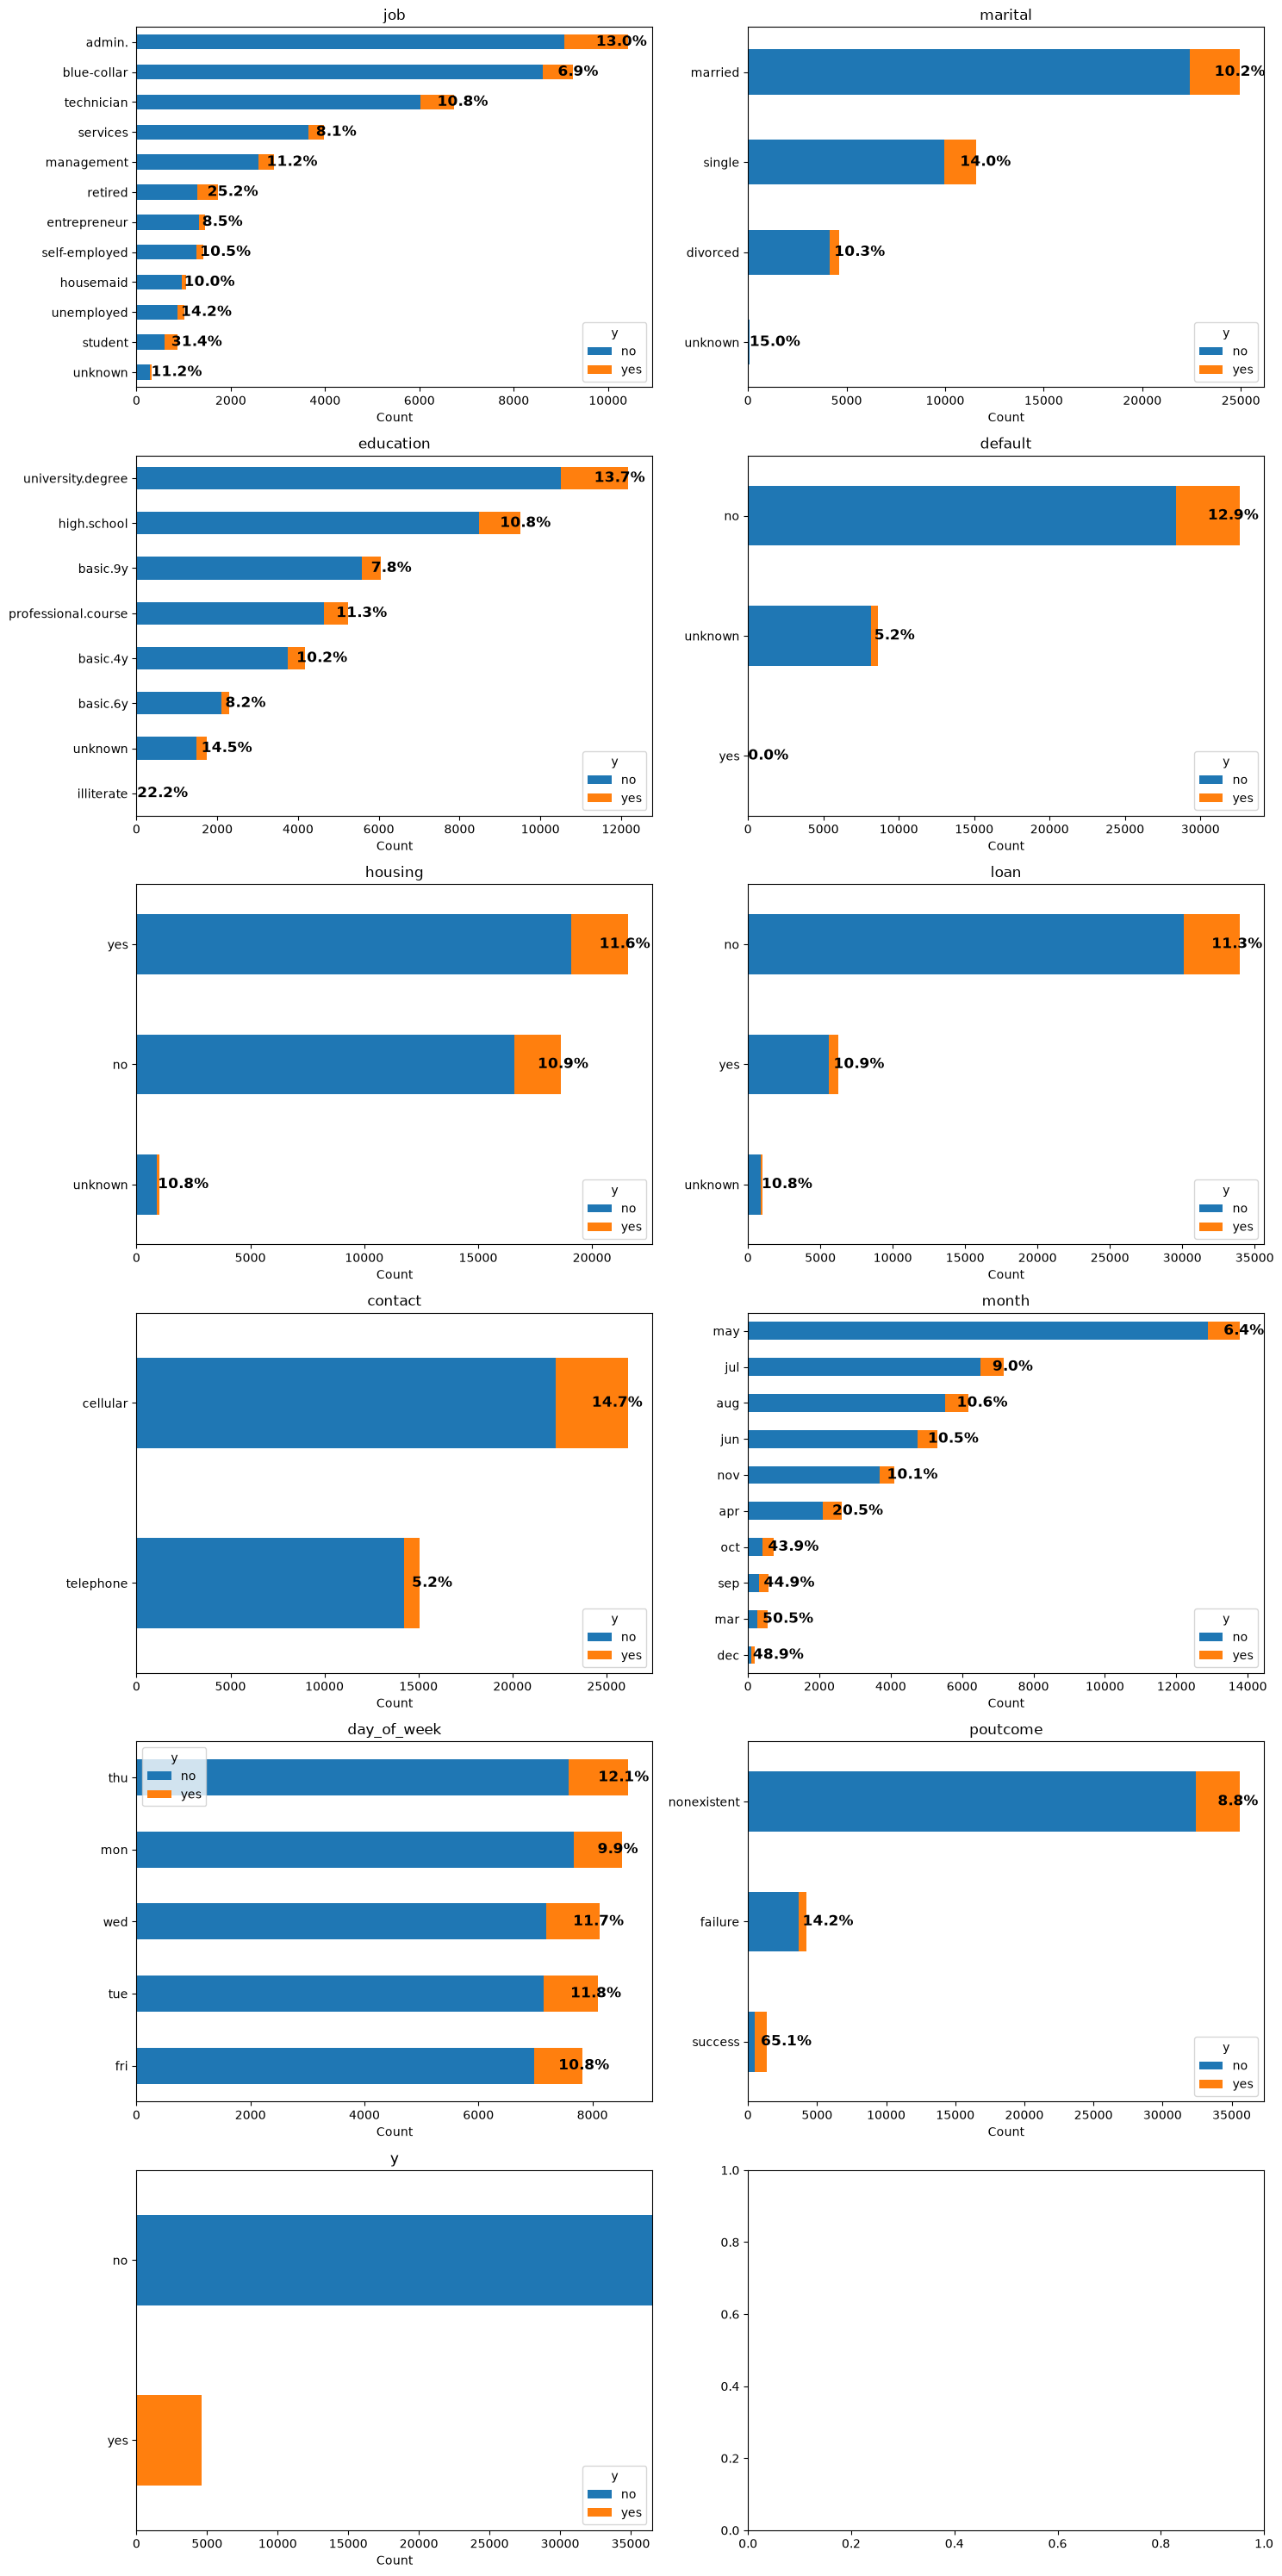

In [7]:
# Se crean gráficas de barras apiladas con las variables categóricas.
fig, axes = plt.subplots(6, 2, figsize=(15, 30))
axes = axes.flatten()

for ax, col in zip(axes, cat_vars):
    # Se crea una tabla de contingencia.
    contingency_table = (
        cat_vars
        .groupby([col, 'y'])
        .size()
        .unstack(fill_value=0)
    )

    # Se ordenan las categorias de las variables de texto de mayor a menor.
    contingency_table = contingency_table.loc[contingency_table.sum(axis=1).sort_values(ascending=True).index]

    # Se crea la grafica de barras.
    contingency_table.plot(
        kind='barh',
        stacked=True,
        ax=ax
    )

    if col != "y":
        proportions = contingency_table.div(contingency_table.sum(axis=1), axis=0)

        for i, (idx, row) in enumerate(contingency_table.iterrows()):
            prop_yes = proportions.loc[idx, "yes"] if "yes" in proportions.columns else 0

            count_no = row.get("no", 0)
            count_yes = row.get("yes", 0)
            
            x_pos = count_no + count_yes / 2

            ax.text(
                x_pos,
                i,
                f"{prop_yes:.1%}",
                va='center',
                ha='left',
                fontsize=12,
                fontweight='bold'
            )


    ax.set_title(col)
    ax.set_xlabel('Count')
    ax.set_ylabel('')
    ax.legend(title='y')

plt.tight_layout()
plt.show()

## 2.2 Hallazgos de las variables categóricas
- El set de datos esta desbalanceado, pues podemos ver, gracias a la variable “y”, que históricamente la mayoría de los clientes del banco no aceptan un depósito a largo plazo.
- En la variable “poutcome” podemos ver que el 65.1% de los clientes que contrataron un depósito a largo plazo, en una campaña publicitaria anterior, volvieron a contratar otro deposito durante la campaña actual.
- En la variable “contact” podemos ver que es mejor contactar a los clientes haciéndoles una llamada a su número celular que a su número telefónico, pues el 14.7% de los clientes que fueron contactados a su número celular contrataron el depósito bancario, mientras que solo el 5.2% de los clientes que fueron contactados a su número telefónico lo contrataron.

## 2.3 Análisis de variables numéricas

In [8]:
# Se obtienen las variables numéricas del set de datos.
num_vars = bank_data_df.select_dtypes(include=['int', "float"])
num_vars.head()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0
3,40,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0
4,56,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0


In [9]:
# Se obtienen sus estadísticas descriptivas.
stats = num_vars.describe().T

stats["skew"] = num_vars.skew()
stats["kurtosis"] = num_vars.kurtosis()

stats

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000,0.784697,0.791312
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000,3.263141,20.247938
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000,4.762507,36.979795
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000,-4.922190,22.229463
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000,3.832042,20.108816
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400,-0.724096,-1.062632
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767,-0.230888,-0.829809
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900,0.303180,-0.358558
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045,-0.709188,-1.406803
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100,-1.044262,-0.003760


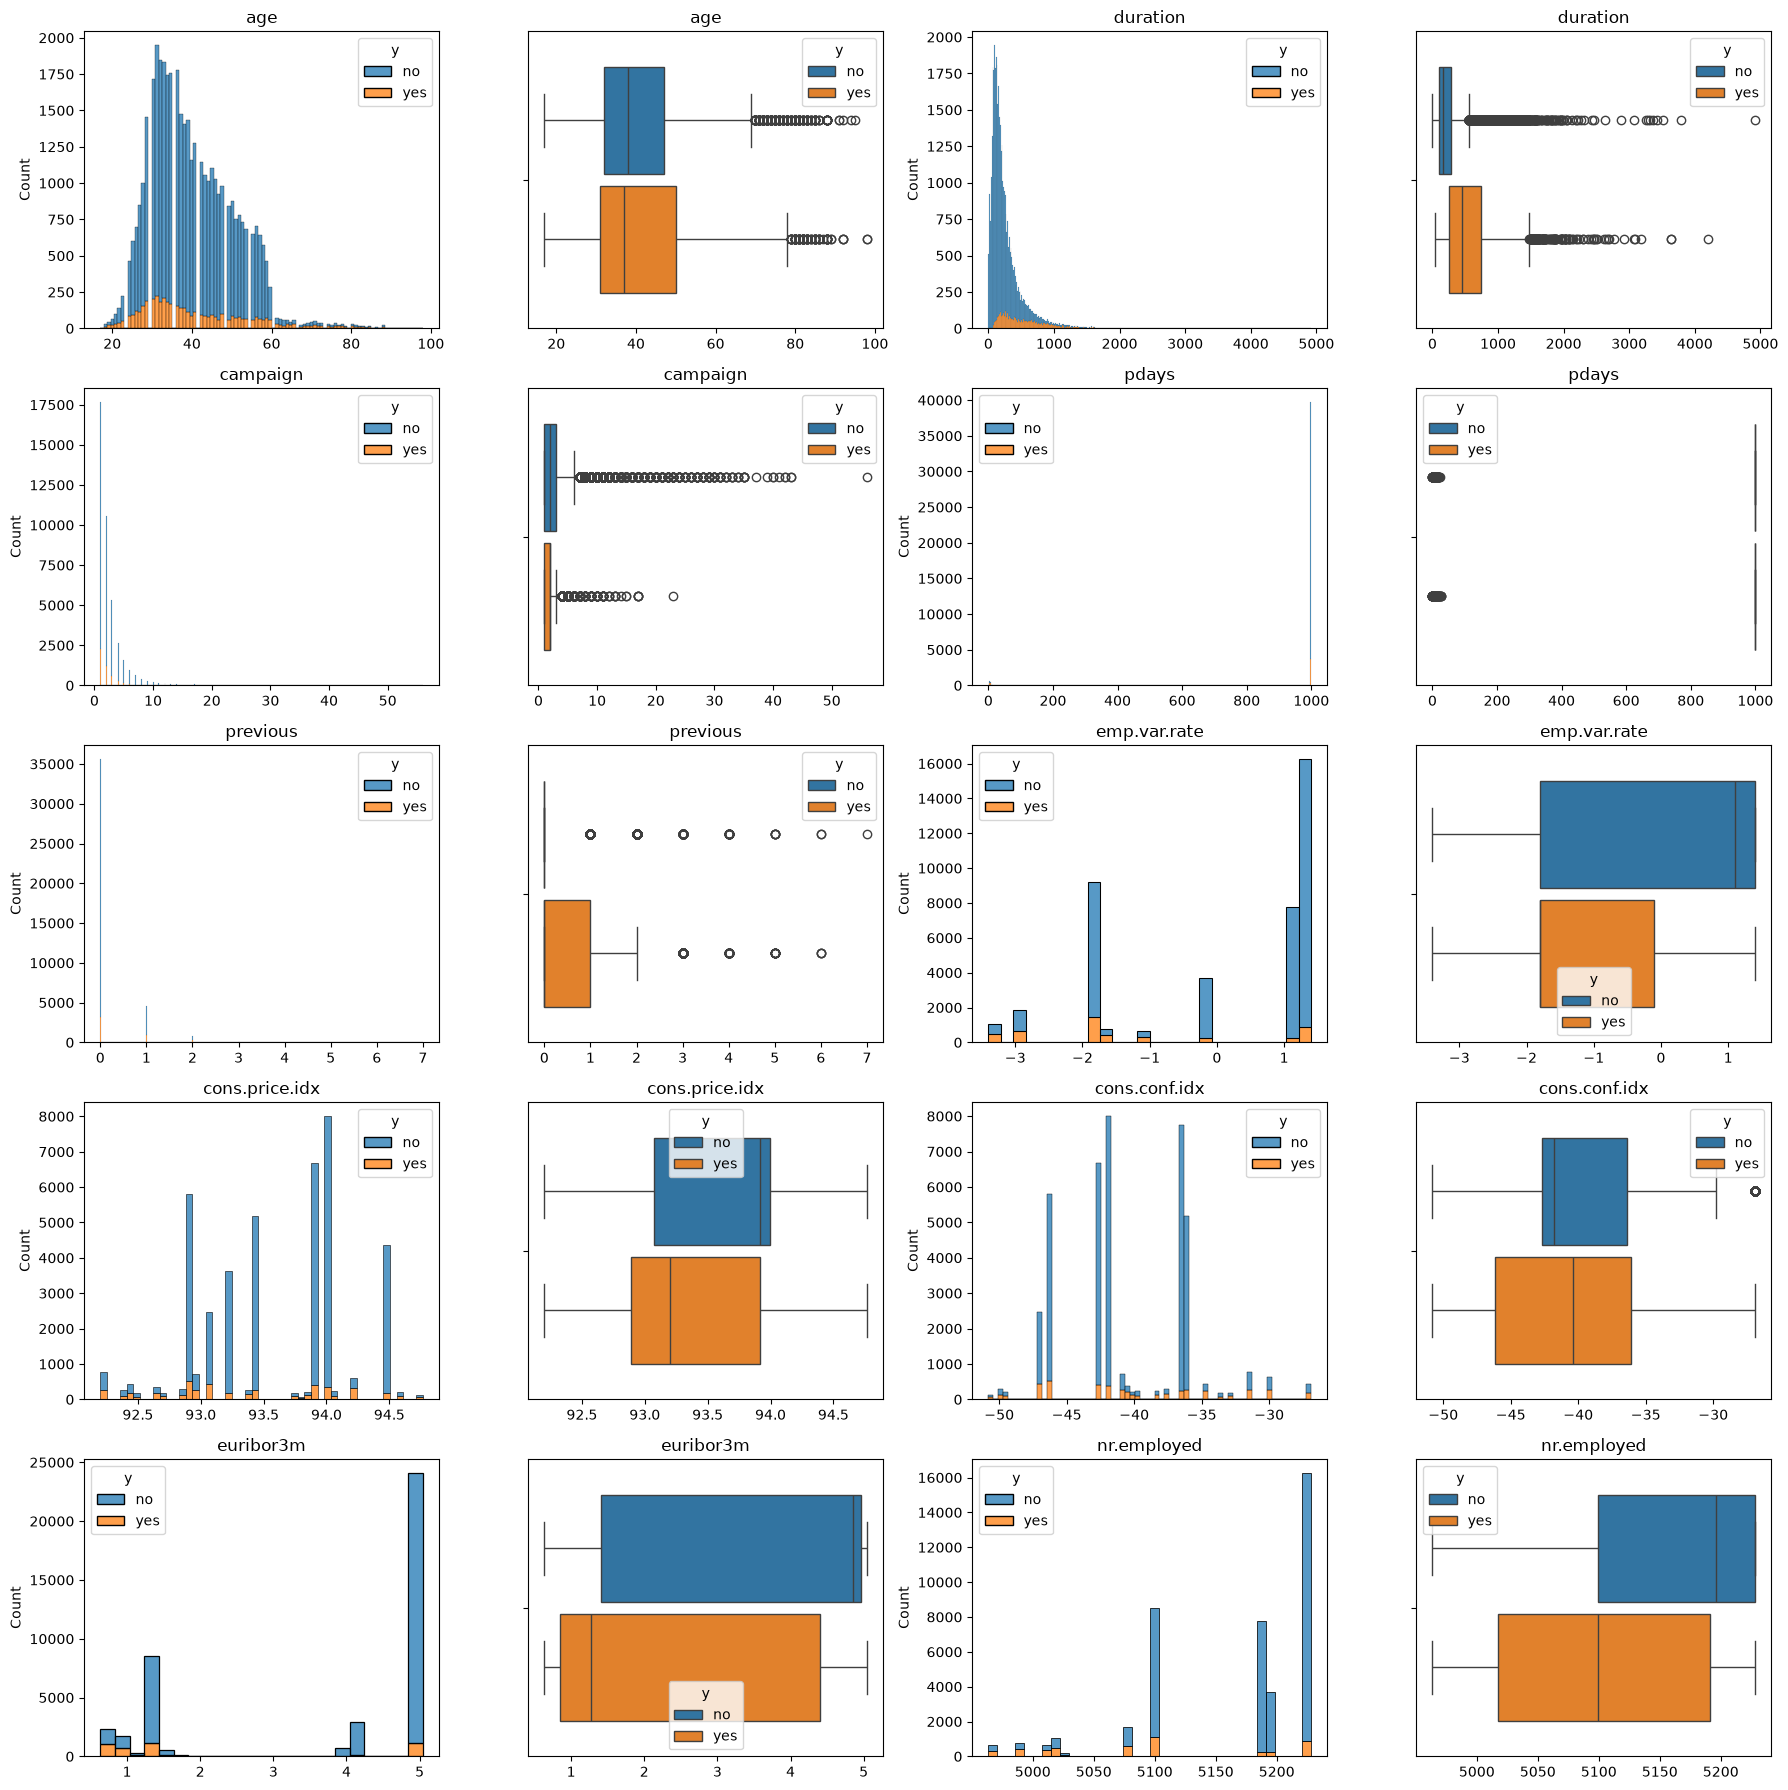

In [10]:
# Se crean histogramas y diagramas de caja y bigote para cada una de las variables numéricas.
fig, axes = plt.subplots(5, 4, figsize=(18, 18))
axes = axes.flatten()

counter = 0

# Por cada variable numérica haz lo siguiente.
for col in num_vars:

    histplot_ax = axes[0+counter]
    boxplot_ax = axes[1+counter]

    # Gráfica un histograma para saber la distribución de la variable.
    sns.histplot(
        data=bank_data_df,
        x=col,
        hue='y',
        hue_order=['no', 'yes'],
        multiple="stack",
        stat='count',
        ax=histplot_ax,
    )
    histplot_ax.set_title(col)
    histplot_ax.set_xlabel("")

    # Gráfica un diagrama de caja y bigote para ver si la distribución de la variable contiene valores atípicos.
    sns.boxplot(
        data=bank_data_df,
        x=col,
        hue='y',
        ax=boxplot_ax,
        gap=0.1
    )
    boxplot_ax.set_title(col)
    boxplot_ax.set_xlabel("")

    counter += 2

plt.tight_layout()
plt.show()

## 2.4 Hallazgos de las variables numéricas
- En la variable “duration” podemos ver que, entre más dure la última llamada que se le hizo a un cliente, mayores son las posibilidades de que contrate el depósito bancario. El único problema es que esta variable no se puede utilizar en el entrenamiento de un modelo, pues sus valores solo los podemos saber en el futuro, y no se pueden usar valores futuros que no se pueden obtener por ningún medio en el entrenamiento de nuestro modelo, por eso eliminaremos esta variable cuando limpiemos los datos.